### **Simple Linear Regression**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
df = pd.read_csv("../dataset/student_scores.csv")
print(df.head())
print(df.describe())

   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30
           Hours     Scores
count  25.000000  25.000000
mean    5.012000  51.480000
std     2.525094  25.286887
min     1.100000  17.000000
25%     2.700000  30.000000
50%     4.800000  47.000000
75%     7.400000  75.000000
max     9.200000  95.000000


In [8]:
X = df['Hours'].values.reshape(-1,1)
Y = df['Scores'].values

In [9]:
X.shape , Y.shape

((25, 1), (25,))

In [12]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X,Y)

slope = model.coef_[0]
intercept = model.intercept_

print(f"Slope (m):{slope: .2f}")
print(f"Intercept (b): {intercept: .2f}")
print(f"Equation: Score = {intercept: .2f} + {slope: .2f} * Hours")

Slope (m): 9.78
Intercept (b):  2.48
Equation: Score =  2.48 +  9.78 * Hours


In [14]:
y_pred = model.predict(X)
new_hours = np.array([[9.25]])
predicted_score = model.predict(new_hours)
print(f"Predicted score for 9.25 hours: {predicted_score[0]: .2f}")

Predicted score for 9.25 hours:  92.91


In [16]:
from sklearn.metrics import r2_score, mean_squared_error

r2 = r2_score(Y,y_pred)
mse = mean_squared_error(Y,y_pred)

print(f"R2 score: {r2: .3f}")
print(f"Mean Squared Error: {mse: .4f}")

R2 score:  0.953
Mean Squared Error:  28.8827


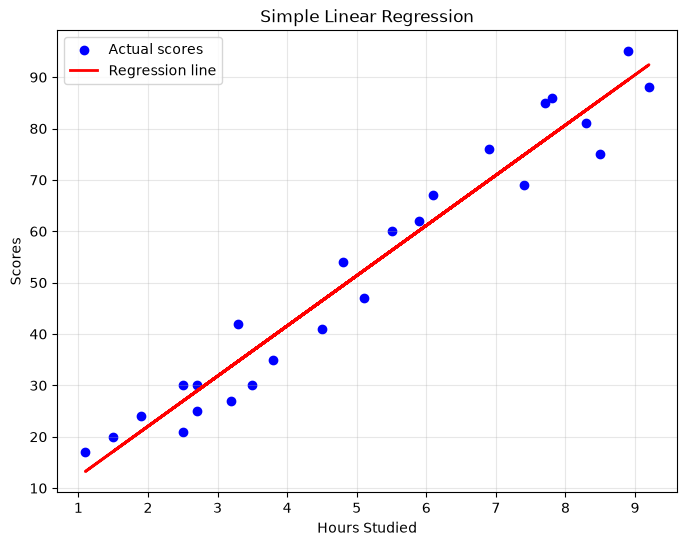

In [19]:
plt.figure(figsize=(8,6))
plt.scatter(X,Y,color='blue', label='Actual scores')
plt.plot(X,y_pred,color='red', linewidth=2, label='Regression line')
plt.xlabel('Hours Studied')
plt.ylabel('Scores')
plt.title('Simple Linear Regression')
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()

In [20]:
import pickle
import os

os.makedirs('models', exist_ok=True)

In [23]:
model_path = 'models/linear_regression_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model, f)
    print(f"Model stored at path: {os.path.abspath(model_path)}")

Model stored at path: c:\Users\harsh bhuvad\OneDrive\Desktop\ML_Project\Simple_Linear_Regression\notebooks\models\linear_regression_model.pkl
